# Task-1

In [1]:
#import libarary
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings

from sklearn.datasets import make_blobs,make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
warnings.filterwarnings("ignore")


In [2]:
#Generate 50 data points distributed around three centres, then scale the features.
X_3, y_3 = make_blobs(
    n_samples=50,
    centers=3,
    cluster_std=0.8,
    random_state=42
)

X_3_scaled = StandardScaler().fit_transform(X_3)

Z_3 = linkage(X_3_scaled, method="ward")

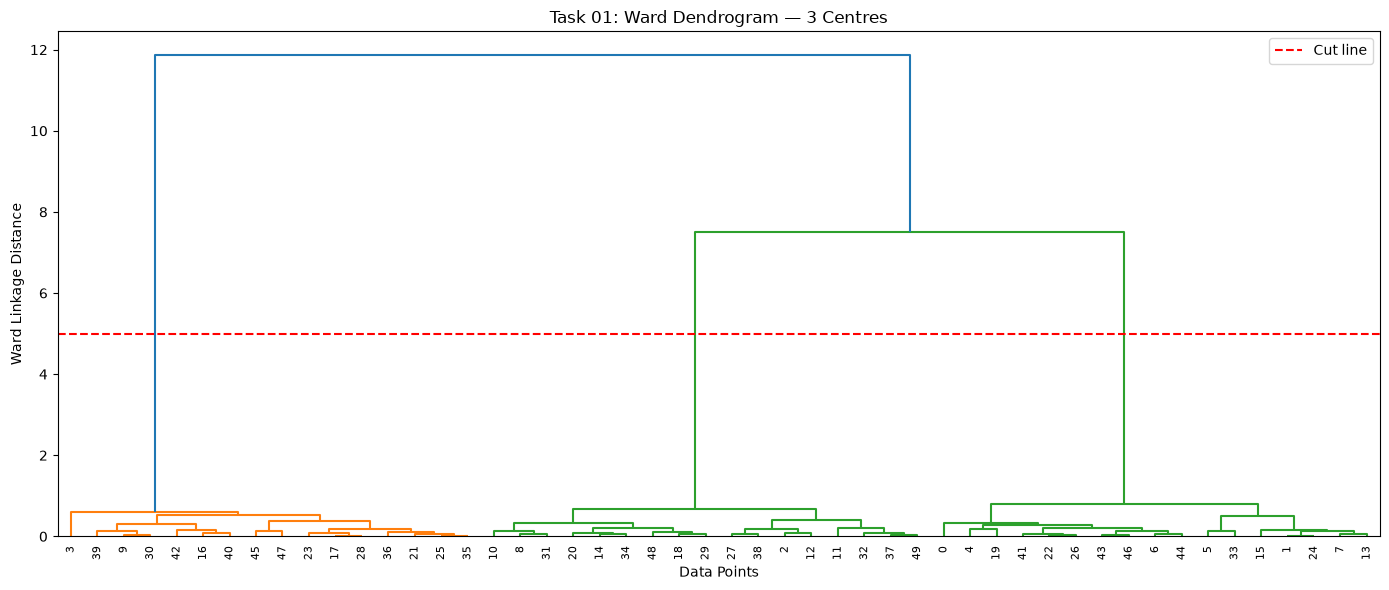

In [3]:
#Plot the dendrogram for 3 centres
plt.figure(figsize=(14, 6))

dendrogram(
    Z_3,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.axhline(y=5, color="red", linestyle="--", label="Cut line")

plt.title("Task 01: Ward Dendrogram — 3 Centres")
plt.xlabel("Data Points")
plt.ylabel("Ward Linkage Distance")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
#Generate data with 5 centres
X_5, y_5 = make_blobs(
    n_samples=50,
    centers=5,
    cluster_std=0.8,
    random_state=42
)

X_5_scaled = StandardScaler().fit_transform(X_5)

Z_5 = linkage(X_5_scaled, method="ward")

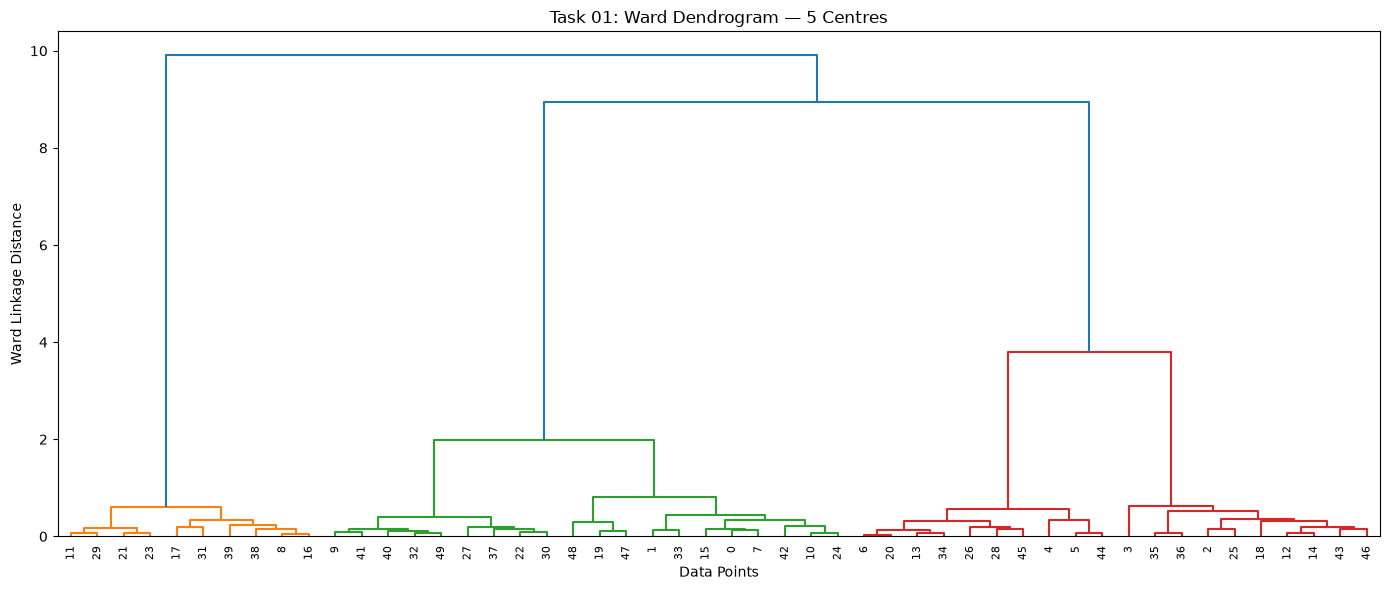

In [5]:
#Plot the dendrogram for 5 centres
plt.figure(figsize=(14, 6))

dendrogram(
    Z_5,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Task 01: Ward Dendrogram — 5 Centres")
plt.xlabel("Data Points")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

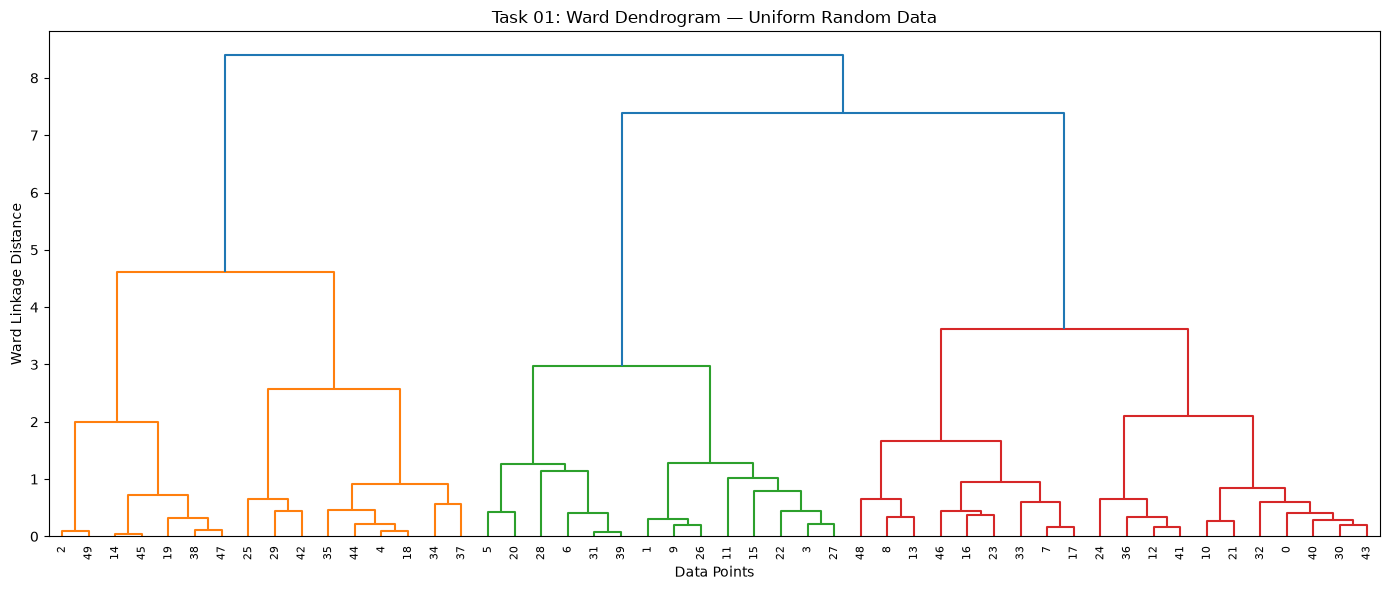

In [6]:
#Test uniform random data
rng = np.random.default_rng(42)

X_uniform = rng.uniform(
    low=-3,
    high=3,
    size=(50, 2)
)

X_uniform_scaled = StandardScaler().fit_transform(X_uniform)

Z_uniform = linkage(X_uniform_scaled, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    Z_uniform,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Task 01: Ward Dendrogram — Uniform Random Data")
plt.xlabel("Data Points")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

1. Why does a long vertical branch indicate a well-separated cluster?
- A long vertical branch indicates that two groups merge only after the linkage distance increases substantially. This suggests that the groups are relatively well separated.

2. How can a dendrogram help determine the number of clusters?
- We look for large vertical gaps between successive merges and draw a horizontal cut through those gaps. The number of branches intersected by the cut gives the number of clusters.

3. What happens with uniform random data?
- Uniform random data generally has no clearly separated groups. Its dendrogram may not contain obvious gaps, making the number of meaningful clusters difficult to determine.

4. What did you learn?
- A dendrogram helps us estimate the number of clusters without choosing it in advance. However, the result depends on the data distribution and the position of the cut line.

# Task-2

In [7]:
# 1. Generate three datasets
datasets = {
    "Blobs": make_blobs(
        n_samples=300,
        centers=3,
        cluster_std=0.8,
        random_state=42
    ),
    "Moons": make_moons(
        n_samples=300,
        noise=0.08,
        random_state=42
    ),
    "Circles": make_circles(
        n_samples=300,
        noise=0.05,
        factor=0.5,
        random_state=42
    )
}

linkage_methods = ["single", "complete", "average", "ward"]
results = []

In [8]:
# 2. Compare all four linkage methods
for shape, (X, y_true) in datasets.items():

    X_scaled = StandardScaler().fit_transform(X)

    # Blobs have 3 clusters; moons and circles have 2
    n_clusters = 3 if shape == "Blobs" else 2

    row = {"Shape": shape}

    for method in linkage_methods:

        model = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=method
        )

        y_pred = model.fit_predict(X_scaled)

        ari = adjusted_rand_score(y_true, y_pred)

        row[method.capitalize()] = round(ari, 4)

    results.append(row)

In [9]:
# 3. Display the comparison table
results_df = pd.DataFrame(results).set_index("Shape")

print("Task 02: Linkage Comparison — ARI Scores")
display(results_df)

Task 02: Linkage Comparison — ARI Scores


,Single,Complete,Average,Ward
Shape,,,,
Blobs,1.0,1.0000,1.0000,1.0000
Moons,1.0,0.7159,0.7159,0.7159
Circles,1.0,-0.0017,0.0014,0.0013


In [10]:
# 4. Identify the best linkage for each shape
print("\nBest linkage for each shape:")

for shape, row in results_df.iterrows():
    best_score = row.max()
    best_methods = row.index[row == best_score].tolist()

    print(
        f"{shape}: {', '.join(best_methods)} "
        f"(ARI = {best_score:.4f})"
    )


Best linkage for each shape:
Blobs: Single, Complete, Average, Ward (ARI = 1.0000)
Moons: Single (ARI = 1.0000)
Circles: Single (ARI = 1.0000)


Single linkage measures the distance between two clusters using the minimum distance between any pair of points, so it can connect nearby points along curved shapes. Complete linkage uses the maximum distance, average linkage uses the average distance, and Ward linkage minimizes the increase in within-cluster variance, making them less suitable for some non-spherical shapes.

# Task-3

In [11]:
X, y_true = make_blobs(
    n_samples=300,
    centers=[(-5, 0), (0, 0), (5, 0)],
    cluster_std=0.6,
    random_state=42
)

X_scaled = StandardScaler().fit_transform(X)

single_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="single"
)

y_single = single_model.fit_predict(X_scaled)

baseline_ari = adjusted_rand_score(y_true, y_single)

print(f"Single Linkage Baseline ARI: {baseline_ari:.4f}")

Single Linkage Baseline ARI: 0.5686


In [12]:
bridge_count = 25

bridge = np.column_stack([
    np.linspace(-4.5, -0.5, bridge_count),
    np.zeros(bridge_count)
])

X_with_bridge = np.vstack([X, bridge])

In [13]:
# Scale the complete dataset before clustering
X_bridge_scaled = StandardScaler().fit_transform(X_with_bridge)

In [14]:
# Give bridge points a separate label for evaluation
y_bridge_true = np.concatenate([
    y_true,
    np.full(bridge_count, -1)
])

In [15]:
# Evaluate single linkage
single_bridge = AgglomerativeClustering(
    n_clusters=3,
    linkage="single"
)

y_single_bridge = single_bridge.fit_predict(X_bridge_scaled)

In [16]:
# Evaluate Ward linkage
ward_bridge = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

y_ward_bridge = ward_bridge.fit_predict(X_bridge_scaled)

In [17]:
# Evaluate ARI on the original 300 points only
single_ari = adjusted_rand_score(
    y_true,
    y_single_bridge[:len(X)]
)

ward_ari = adjusted_rand_score(
    y_true,
    y_ward_bridge[:len(X)]
)

print(f"Single Linkage ARI: {single_ari:.4f}")
print(f"Ward Linkage ARI:   {ward_ari:.4f}")

Single Linkage ARI: 0.5686
Ward Linkage ARI:   0.5059


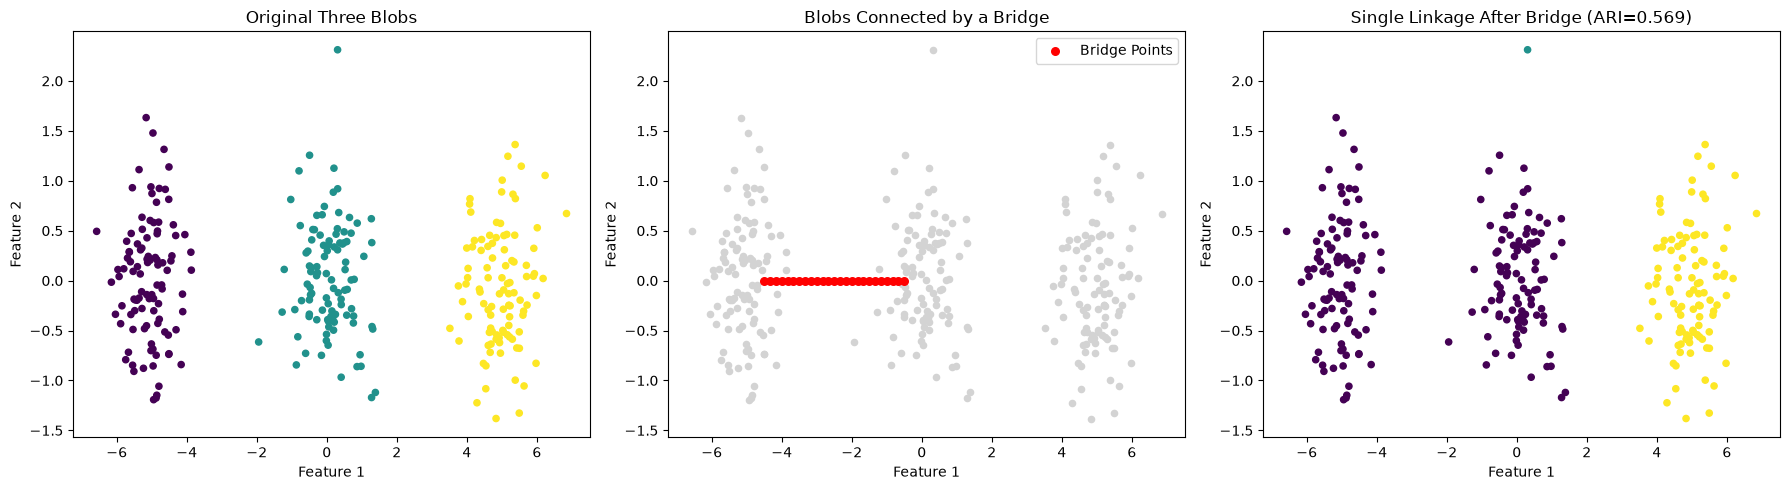

In [18]:
#visualize the bridge experiment
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X[:, 0], X[:, 1], c=y_true, cmap="viridis", s=20)
axes[0].set_title("Original Three Blobs")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

axes[1].scatter(
    X_with_bridge[:, 0],
    X_with_bridge[:, 1],
    c="lightgray",
    s=20
)
axes[1].scatter(
    bridge[:, 0],
    bridge[:, 1],
    color="red",
    s=30,
    label="Bridge Points"
)
axes[1].set_title("Blobs Connected by a Bridge")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend()

axes[2].scatter(
    X[:, 0],
    X[:, 1],
    c=y_single_bridge[:len(X)],
    cmap="viridis",
    s=20
)
axes[2].set_title(f"Single Linkage After Bridge (ARI={single_ari:.3f})")
axes[2].set_xlabel("Feature 1")
axes[2].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [19]:
bridge_sizes = [10, 25, 50, 100]
bridge_results = []

for n_bridge in bridge_sizes:

    bridge = np.column_stack([
        np.linspace(-4.5, -0.5, n_bridge),
        np.zeros(n_bridge)
    ])

    X_combined = np.vstack([X, bridge])
    X_combined_scaled = StandardScaler().fit_transform(X_combined)

    single_model = AgglomerativeClustering(
        n_clusters=3,
        linkage="single"
    )

    predicted = single_model.fit_predict(X_combined_scaled)

    ari = adjusted_rand_score(
        y_true,
        predicted[:len(X)]
    )

    bridge_results.append({
        "Bridge Points": n_bridge,
        "Single Linkage ARI": round(ari, 4)
    })

bridge_results_df = pd.DataFrame(bridge_results)

display(bridge_results_df)

,Bridge Points,Single Linkage ARI
0,10,0.5686
1,25,0.5686
2,50,0.5686
3,100,0.5686


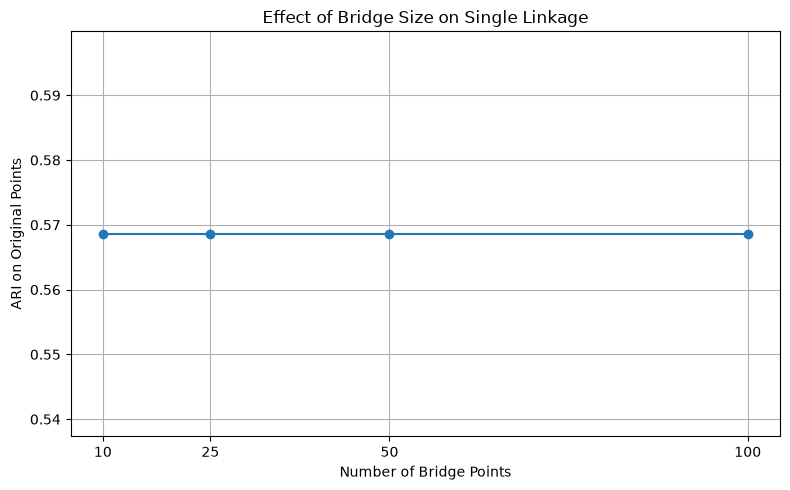

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    bridge_results_df["Bridge Points"],
    bridge_results_df["Single Linkage ARI"],
    marker="o"
)

plt.title("Effect of Bridge Size on Single Linkage")
plt.xlabel("Number of Bridge Points")
plt.ylabel("ARI on Original Points")
plt.xticks(bridge_sizes)
plt.grid(True)
plt.tight_layout()
plt.show()

Single linkage suffers from the chaining effect, where a sequence of nearby points connects two otherwise separate clusters. Because it measures the minimum distance between clusters, even a thin bridge of points can cause the clusters to merge. This weakness can affect real-world applications such as customer segmentation, geographic clustering, and scientific datasets when noise or intermediate points connect distinct groups. Ward linkage is generally less sensitive to this particular problem because it considers the increase in within-cluster variance when merging clusters.

# Task-4

In [21]:
# 1. Generate the moons dataset
X, y_true = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

In [22]:
# 2. Scale the dataset
X_scaled = StandardScaler().fit_transform(X)

In [23]:
# 3. Define eps values
eps_values = np.arange(0.05, 1.01, 0.05)

results = []

In [24]:
# 4. Run DBSCAN for each eps value
for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    y_pred = model.fit_predict(X_scaled)

    # Count clusters, excluding noise label -1
    n_clusters = len(set(y_pred) - {-1})

    # Count noise points
    n_noise = np.sum(y_pred == -1)

    # Calculate ARI
    ari = adjusted_rand_score(y_true, y_pred)

    results.append({
        "eps": round(eps, 2),
        "Number of Clusters": n_clusters,
        "Noise Points": int(n_noise),
        "ARI": round(ari, 4)
    })

In [25]:
# 5. Display the results table
results_df = pd.DataFrame(results)

print("Task 04: DBSCAN eps Sweep")
display(results_df)

Task 04: DBSCAN eps Sweep


,eps,Number of Clusters,Noise Points,ARI
0,0.05,0,300,0.0000
1,0.10,15,202,0.0347
2,0.15,18,53,0.1291
3,0.20,7,10,0.5435
4,0.25,2,2,0.9867
5,0.30,2,0,1.0000
6,0.35,2,0,1.0000
7,0.40,2,0,1.0000
8,0.45,1,0,0.0000
9,0.50,1,0,0.0000


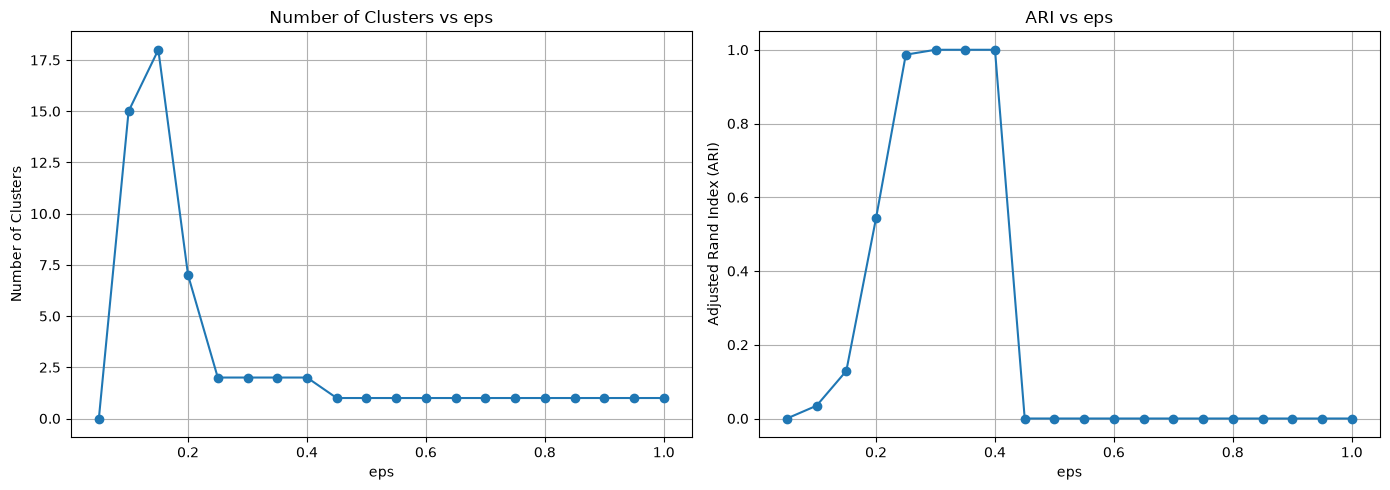

In [26]:
# 6. Plot cluster count and ARI against eps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    results_df["eps"],
    results_df["Number of Clusters"],
    marker="o"
)
axes[0].set_title("Number of Clusters vs eps")
axes[0].set_xlabel("eps")
axes[0].set_ylabel("Number of Clusters")
axes[0].grid(True)

axes[1].plot(
    results_df["eps"],
    results_df["ARI"],
    marker="o"
)
axes[1].set_title("ARI vs eps")
axes[1].set_xlabel("eps")
axes[1].set_ylabel("Adjusted Rand Index (ARI)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
# 7. Display the best eps based on ARI
best_row = results_df.loc[results_df["ARI"].idxmax()]

print("\nBest eps based on ARI:")
print(f"eps: {best_row['eps']}")
print(f"Clusters: {best_row['Number of Clusters']}")
print(f"Noise points: {best_row['Noise Points']}")
print(f"ARI: {best_row['ARI']}")


Best eps based on ARI:
eps: 0.3
Clusters: 2.0
Noise points: 0.0
ARI: 1.0


- DBSCAN's performance depends heavily on the choice of eps. When eps is too small, many points become noise or the data is divided into too many small clusters. When eps is too large, separate clusters can merge into one. In the moons experiment, eps = 0.30 produced two clusters with zero noise points and an ARI of 1.0000, while eps = 0.05 classified all 300 points as noise and eps = 0.45 merged the moons into one cluster. Therefore, choosing an appropriate eps is essential for successful density-based clustering.

# Task-5

In [28]:
# 1. Generate and scale both datasets
X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

X_circles, y_circles = make_circles(
    n_samples=300,
    noise=0.05,
    factor=0.5,
    random_state=42
)

X_moons_scaled = StandardScaler().fit_transform(X_moons)
X_circles_scaled = StandardScaler().fit_transform(X_circles)

datasets = {
    "Moons": (X_moons_scaled, y_moons),
    "Circles": (X_circles_scaled, y_circles)
}

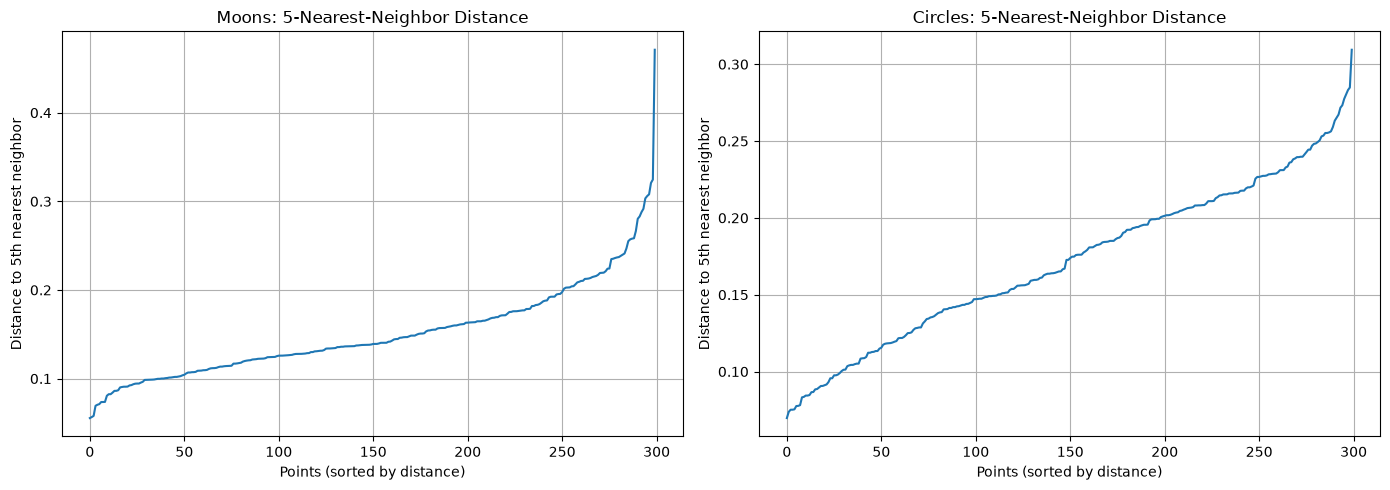

In [29]:
# 2. Build k-distance plots using k=5
k = 5
k_distances = {}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, (X_scaled, y_true)) in zip(
    axes, datasets.items()
):
    neighbors = NearestNeighbors(n_neighbors=k)
    neighbors.fit(X_scaled)

    distances, _ = neighbors.kneighbors(X_scaled)

    # The distance to the 5th neighbor,
    # counting the point itself as a neighbor
    distances_sorted = np.sort(distances[:, -1])

    k_distances[name] = distances_sorted

    ax.plot(distances_sorted)
    ax.set_title(f"{name}: 5-Nearest-Neighbor Distance")
    ax.set_xlabel("Points (sorted by distance)")
    ax.set_ylabel("Distance to 5th nearest neighbor")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [30]:
# 3. Choose eps from the plots BEFORE checking ARI
print("Inspect both plots and identify the bend in each curve.")
print("Enter your chosen eps values based on the plots.")

eps_moons = float(input("Your chosen eps for Moons: "))
eps_circles = float(input("Your chosen eps for Circles: "))

chosen_eps = {
    "Moons": eps_moons,
    "Circles": eps_circles
}

Inspect both plots and identify the bend in each curve.
Enter your chosen eps values based on the plots.


In [31]:
# 4. Run DBSCAN and evaluate the choices
results = []

for name, (X_scaled, y_true) in datasets.items():

    eps = chosen_eps[name]

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = int(np.sum(labels == -1))
    ari = adjusted_rand_score(y_true, labels)

    results.append({
        "Dataset": name,
        "Chosen eps": eps,
        "Clusters": n_clusters,
        "Noise Points": n_noise,
        "ARI": round(ari, 4)
    })

In [32]:
# 5. Display the final comparison
task5_results = pd.DataFrame(results)

print("\nTask 05: K-Distance Method Results")
display(task5_results)


Task 05: K-Distance Method Results


,Dataset,Chosen eps,Clusters,Noise Points,ARI
0,Moons,0.30,2,0,1.0
1,Circles,0.35,2,0,1.0


- The k-distance method estimates a suitable eps value by identifying the bend in the sorted nearest-neighbor distance curve. I selected eps for the moons and circles datasets before checking their ARI scores, then evaluated the resulting clusters using ARI, cluster count, and noise count. The method provides a useful starting point when true labels are unavailable, but the bend can be subjective and does not guarantee the best clustering result. Therefore, k-distance plots should be combined with visual inspection and other clustering diagnostics.

# Task-6

In [33]:
# 1. Generate three slightly overlapping clusters
X, y_true = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.5,
    random_state=42
)

In [34]:
# 2. Scale the features
X_scaled = StandardScaler().fit_transform(X)

In [35]:
# 3. Fit GMM with three components
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42,
    n_init=5
)

gmm.fit(X_scaled)

,"n_components n_components: int, default=1The number of mixture components.",3
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [36]:
# 4. Get membership probabilities
probabilities = gmm.predict_proba(X_scaled)

In [37]:
# 5. Find each point's highest membership probability
confidence = probabilities.max(axis=1)

In [38]:
# 6. Identify uncertain points
uncertain_mask = confidence < 0.6
uncertain_count = int(uncertain_mask.sum())

print(f"Total data points: {len(X)}")
print(f"Uncertain points (confidence < 0.6): {uncertain_count}")
print(f"Confident points (confidence >= 0.6): {len(X) - uncertain_count}")

Total data points: 300
Uncertain points (confidence < 0.6): 0
Confident points (confidence >= 0.6): 300


In [39]:
# 7. Display the probabilities of the first 10 points
probability_df = pd.DataFrame(
    probabilities,
    columns=["Cluster 0 Probability", "Cluster 1 Probability", "Cluster 2 Probability"]
)

probability_df["Highest Probability"] = confidence
probability_df["Uncertain"] = uncertain_mask

display(probability_df.head(10))

,Cluster 0 Probability,Cluster 1 Probability,Cluster 2 Probability,Highest Probability,Uncertain
0,1.173437e-31,1.000000e+00,4.696596e-29,1.000000,False
1,4.534277e-30,1.000000e+00,8.496331e-29,1.000000,False
2,9.999931e-01,1.062078e-21,6.935062e-06,0.999993,False
3,4.551183e-10,2.255066e-21,1.000000e+00,1.000000,False
4,7.472596e-35,1.000000e+00,3.232330e-35,1.000000,False
5,3.749772e-16,1.041673e-21,1.000000e+00,1.000000,False
6,1.000000e+00,9.363058e-29,1.096606e-10,1.000000,False
7,1.211776e-15,2.242550e-19,1.000000e+00,1.000000,False
8,1.000000e+00,1.334821e-25,1.267141e-10,1.000000,False
9,1.000000e+00,6.161849e-29,1.236882e-13,1.000000,False


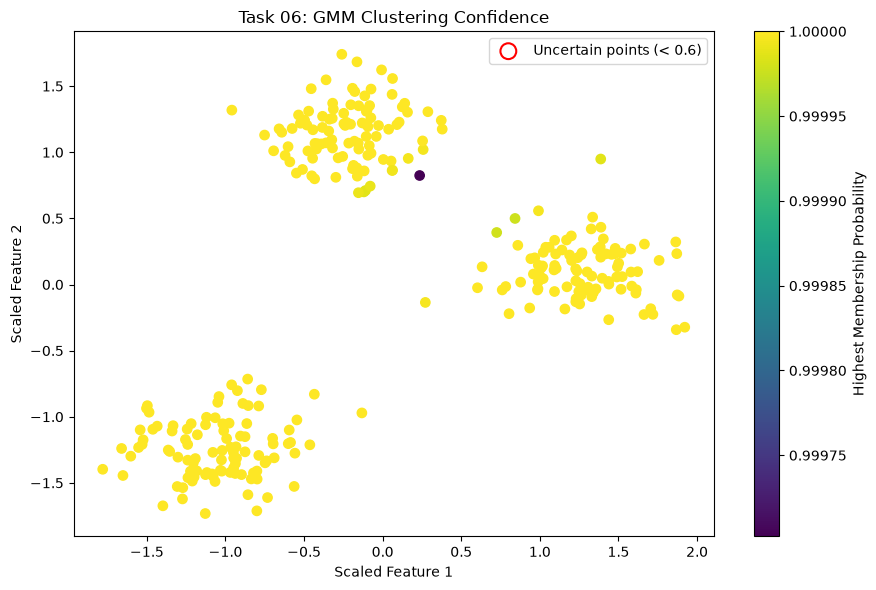

In [40]:
# 8. Visualize points by confidence
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=confidence,
    cmap="viridis",
    s=45
)

plt.scatter(
    X_scaled[uncertain_mask, 0],
    X_scaled[uncertain_mask, 1],
    facecolors="none",
    edgecolors="red",
    s=130,
    linewidths=1.5,
    label="Uncertain points (< 0.6)"
)

plt.colorbar(scatter, label="Highest Membership Probability")
plt.title("Task 06: GMM Clustering Confidence")
plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

- Gaussian Mixture Models perform soft clustering by estimating the probability that each data point belongs to each cluster. In this experiment, points with a maximum membership probability below 0.6 are identified as uncertain. These points are generally found near overlapping cluster boundaries because their features are compatible with multiple clusters. In customer segmentation, identifying uncertain customers can help businesses avoid making overly confident decisions and instead provide more flexible recommendations.

# Task-7

In [41]:
# 1. GENERATE FOUR DATASETS

X_blobs, y_blobs = make_blobs(
    n_samples=400,
    centers=3,
    cluster_std=0.7,
    random_state=42
)

X_moons, y_moons = make_moons(
    n_samples=400,
    noise=0.08,
    random_state=42
)

X_circles, y_circles = make_circles(
    n_samples=400,
    noise=0.05,
    factor=0.5,
    random_state=42
)

# Generate elongated, stretched blobs
X_stretched, y_stretched = make_blobs(
    n_samples=400,
    centers=3,
    cluster_std=0.7,
    random_state=42
)

# Stretch and rotate the blob data using a linear transformation
transformation = np.array([
    [3.0, 1.5],
    [0.2, 0.5]
])

X_stretched = X_stretched @ transformation

# Store all datasets and their true labels
datasets = {
    "Blobs": (X_blobs, y_blobs, 3),
    "Moons": (X_moons, y_moons, 2),
    "Circles": (X_circles, y_circles, 2),
    "Stretched Blobs": (X_stretched, y_stretched, 3)
}

In [42]:
# 2. DEFINE METHODS AND SETTINGS

dbscan_eps = 0.35
dbscan_min_samples = 5

method_names = [
    "K-Means",
    "Ward",
    "Single",
    "DBSCAN",
    "GMM"
]

ari_results = []
cluster_results = []
plot_results = {}

In [43]:
# 3. SCALE DATA AND RUN ALL FIVE METHODS

for shape, (X, y_true, k) in datasets.items():

    # Scale every dataset before clustering
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # K-Means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels_kmeans = kmeans.fit_predict(X_scaled)

    # Hierarchical clustering: Ward
    ward = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels_ward = ward.fit_predict(X_scaled)

    # Hierarchical clustering: Single
    single = AgglomerativeClustering(
        n_clusters=k,
        linkage="single"
    )
    labels_single = single.fit_predict(X_scaled)

    # DBSCAN: same eps and min_samples for every dataset
    dbscan = DBSCAN(
        eps=dbscan_eps,
        min_samples=dbscan_min_samples
    )
    labels_dbscan = dbscan.fit_predict(X_scaled)

    # Gaussian Mixture Model
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=5
    )
    gmm.fit(X_scaled)
    labels_gmm = gmm.predict(X_scaled)

    # Collect predictions
    predictions = {
        "K-Means": labels_kmeans,
        "Ward": labels_ward,
        "Single": labels_single,
        "DBSCAN": labels_dbscan,
        "GMM": labels_gmm
    }

    ari_row = {"Shape": shape}
    cluster_row = {"Shape": shape}

    # Calculate ARI and number of clusters
    for method_name, labels in predictions.items():

        ari = adjusted_rand_score(y_true, labels)

        ari_row[method_name] = round(ari, 4)

        # Exclude DBSCAN noise label -1 from cluster count
        n_clusters_found = len(set(labels) - {-1})

        cluster_row[method_name] = n_clusters_found

        # Save labels and scaled data for plotting
        plot_results[(shape, method_name)] = (
            X_scaled,
            labels
        )

    ari_results.append(ari_row)
    cluster_results.append(cluster_row)

In [44]:
# 4. DISPLAY THE ARI COMPARISON TABLE

ari_df = pd.DataFrame(ari_results).set_index("Shape")

print("TASK 07: FULL BAKE-OFF — ARI COMPARISON")
display(ari_df)

TASK 07: FULL BAKE-OFF — ARI COMPARISON


,K-Means,Ward,Single,DBSCAN,GMM
Shape,,,,,
Blobs,1.0000,1.0000,1.0,1.000,1.0000
Moons,0.4748,0.4749,1.0,0.995,0.4817
Circles,-0.0024,0.0201,1.0,1.000,-0.0024
Stretched Blobs,1.0000,1.0000,1.0,1.000,1.0000


In [45]:
# 5. DISPLAY NUMBER OF CLUSTERS FOUND

cluster_df = pd.DataFrame(cluster_results).set_index("Shape")

print("Number of Clusters Found by Each Method")
display(cluster_df)

print(f"DBSCAN settings used for all datasets: eps={dbscan_eps}, "
      f"min_samples={dbscan_min_samples}")

Number of Clusters Found by Each Method


,K-Means,Ward,Single,DBSCAN,GMM
Shape,,,,,
Blobs,3,3,3,3,3
Moons,2,2,2,2,2
Circles,2,2,2,2,2
Stretched Blobs,3,3,3,3,3


DBSCAN settings used for all datasets: eps=0.35, min_samples=5


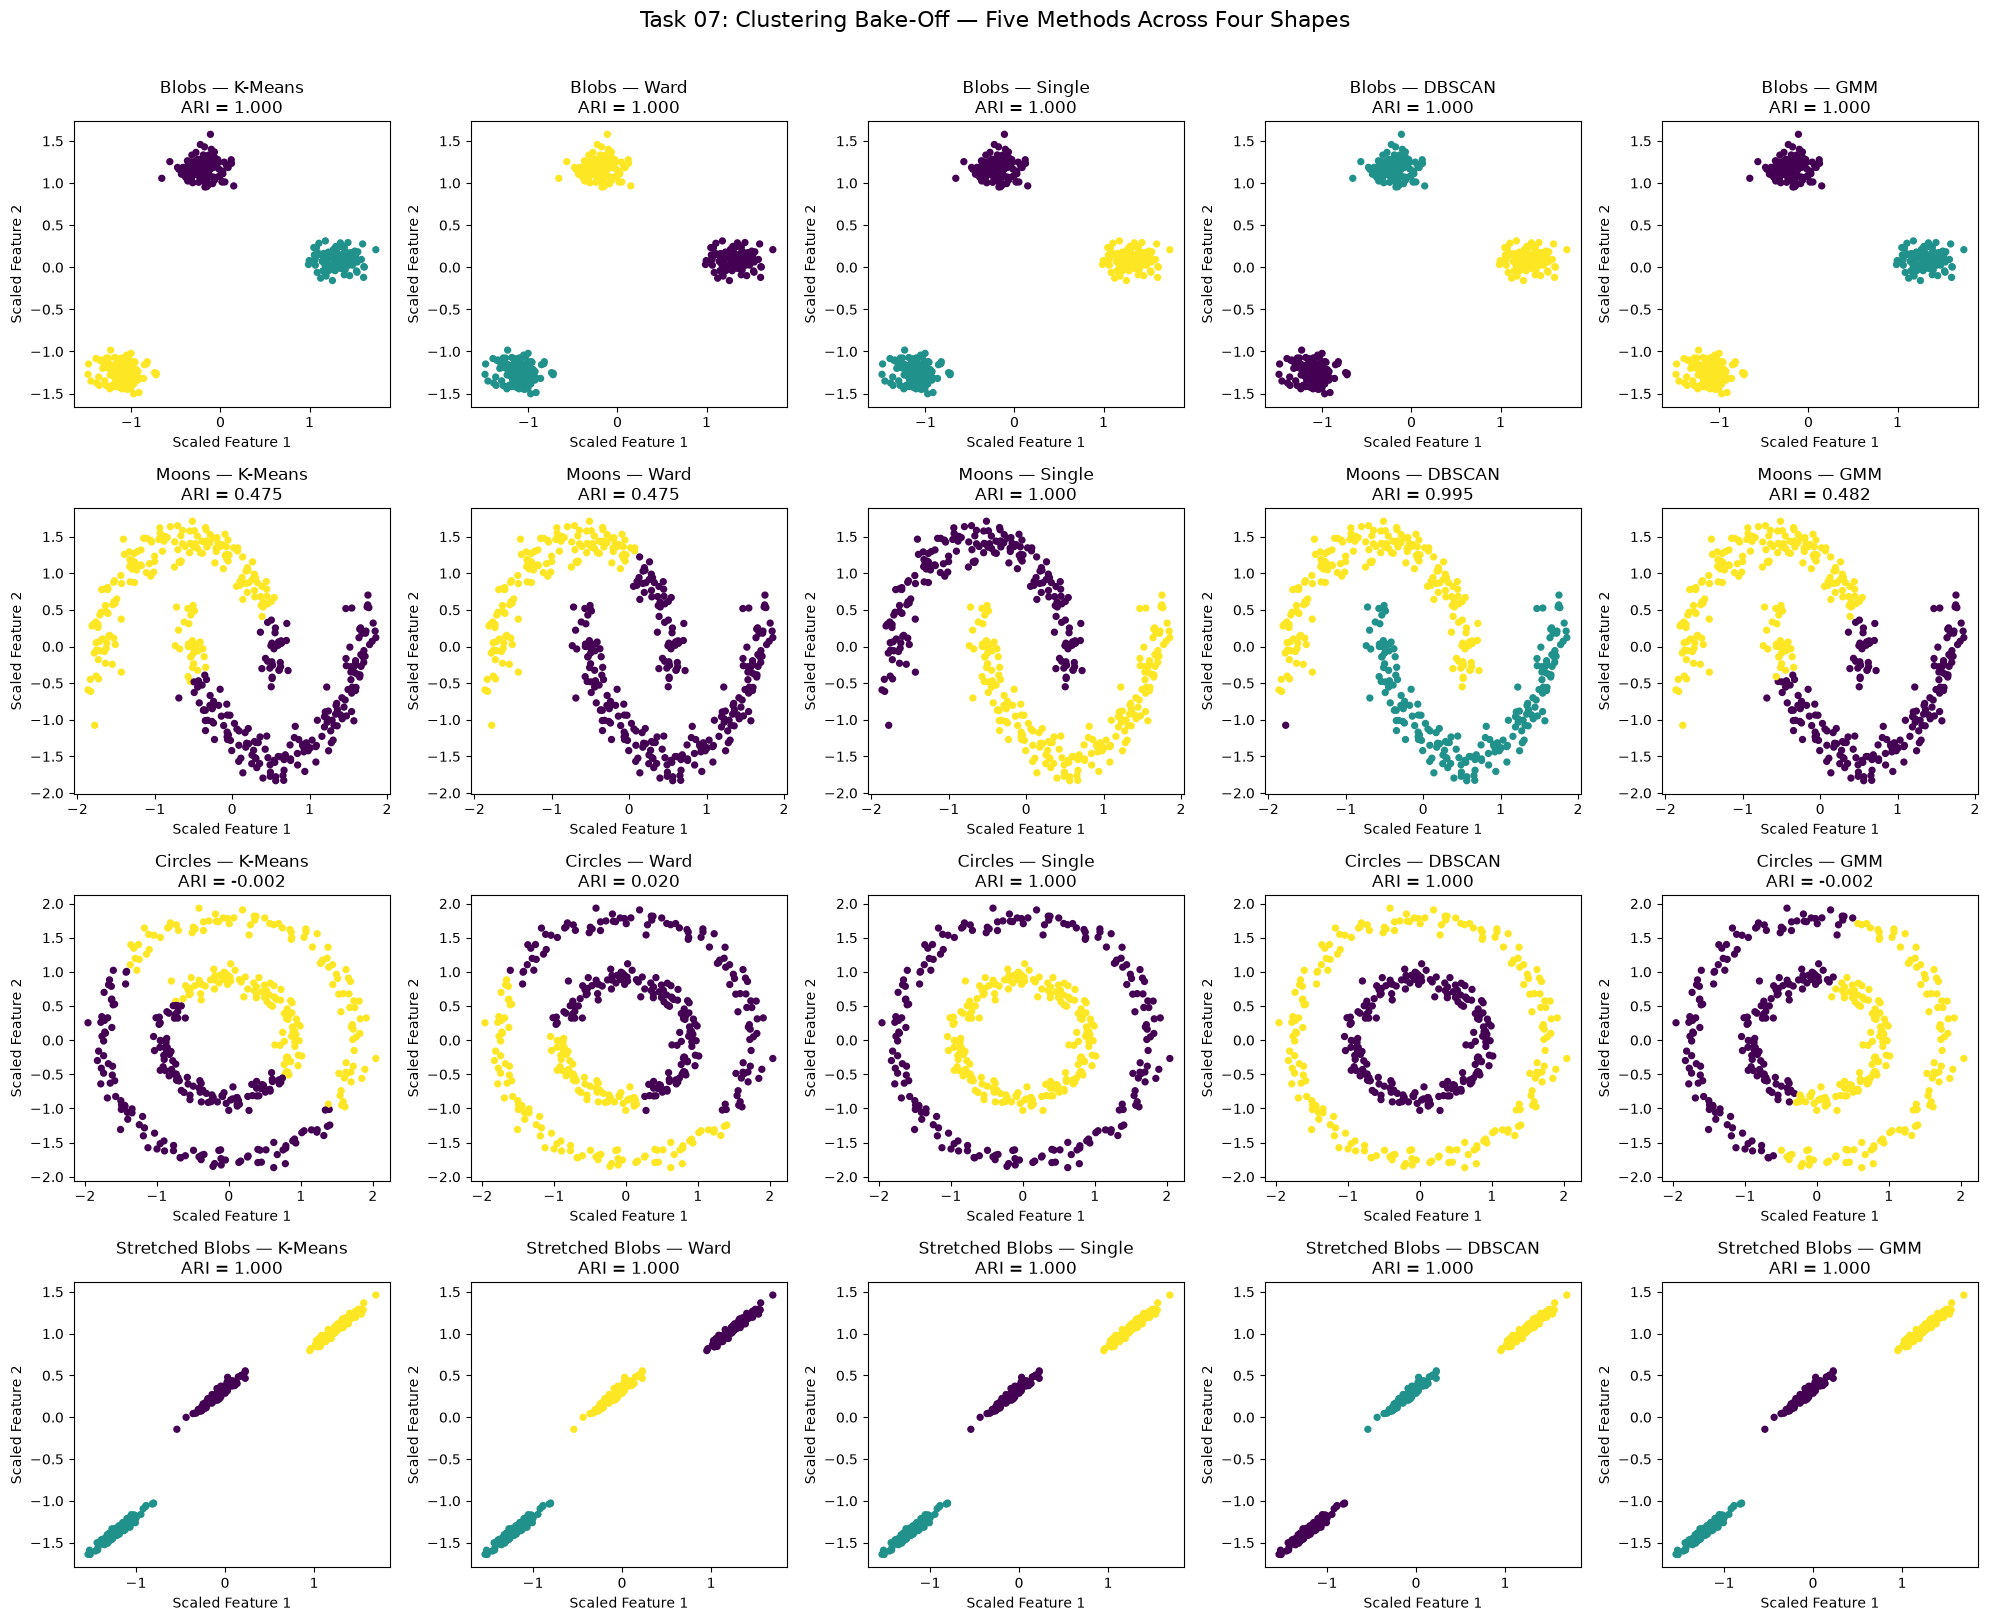

In [46]:
# 6. PLOT GRID: FOUR SHAPES × FIVE METHODS

fig, axes = plt.subplots(
    nrows=4,
    ncols=5,
    figsize=(20, 16)
)

for row_idx, shape in enumerate(datasets.keys()):

    X, y_true, k = datasets[shape]

    for col_idx, method_name in enumerate(method_names):

        ax = axes[row_idx, col_idx]

        X_scaled, labels = plot_results[(shape, method_name)]

        ari = ari_df.loc[shape, method_name]

        ax.scatter(
            X_scaled[:, 0],
            X_scaled[:, 1],
            c=labels,
            cmap="viridis",
            s=18
        )

        ax.set_title(
            f"{shape} — {method_name}\nARI = {ari:.3f}"
        )

        ax.set_xlabel("Scaled Feature 1")
        ax.set_ylabel("Scaled Feature 2")

plt.suptitle(
    "Task 07: Clustering Bake-Off — Five Methods Across Four Shapes",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [47]:
# 7. IDENTIFY THE HIGHEST-ARI METHOD FOR EACH SHAPE

print("WINNER FOR EACH SHAPE")

for shape, row in ari_df.iterrows():

    highest_ari = row.max()

    winners = row.index[
        np.isclose(row.values, highest_ari)
    ].tolist()

    print(
        f"{shape}: {', '.join(winners)} "
        f"(ARI = {highest_ari:.4f})"
    )

WINNER FOR EACH SHAPE
Blobs: K-Means, Ward, Single, DBSCAN, GMM (ARI = 1.0000)
Moons: Single (ARI = 1.0000)
Circles: Single, DBSCAN (ARI = 1.0000)
Stretched Blobs: K-Means, Ward, Single, DBSCAN, GMM (ARI = 1.0000)


- There is no single best clustering method for every dataset. In my experiments, K-Means, Ward, Single Linkage, DBSCAN, and GMM all performed equally well on blobs, each achieving an ARI of 1.0000. Single Linkage performed best on moons with an ARI of 1.0000, while Single Linkage and DBSCAN both performed best on circles with an ARI of 1.0000. For stretched blobs, all five methods achieved an ARI of 1.0000.

- These results show that clustering performance depends on the shape and distribution of the data. K-Means and Ward are useful for compact groups, while Single Linkage and DBSCAN can identify non-spherical shapes under suitable conditions. GMM is useful for modelling Gaussian clusters and estimating membership probabilities. In my experiment, K-Means, Ward, and GMM achieved ARI scores of approximately 0.475 on moons, while Single Linkage achieved 1.0000. Similarly, K-Means and GMM struggled with circles, achieving ARI scores close to 0.0000, whereas Single Linkage and DBSCAN achieved 1.0000. Therefore, I would select a clustering method based on the data structure and the purpose of the analysis rather than assuming that one method is always the best.

# Task-8

In [48]:
# 1. Load the customer dataset
df = pd.read_csv("customer_rfm.csv")

# Select RFM features; customer_id is not used for clustering
features = ["recency_days", "frequency", "monetary"]
X = df[features].copy()

# Handle missing values in the clustering features
valid_rows = X.notna().all(axis=1)
df = df.loc[valid_rows].copy()
X = X.loc[valid_rows].copy()

In [49]:
# 2. Scale the RFM features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset shape:", df.shape)
print("\nRFM features used:", features)

Dataset shape: (1500, 4)

RFM features used: ['recency_days', 'frequency', 'monetary']


In [50]:
# 3. Fit GMM models for K = 2 to 8 and compare BIC
bic_results = []
gmm_models = {}

for k in range(2, 9):
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=5
    )

    gmm.fit(X_scaled)

    bic = gmm.bic(X_scaled)
    bic_results.append({"K": k, "BIC": bic})
    gmm_models[k] = gmm

bic_df = pd.DataFrame(bic_results)

print("\n--- GMM BIC Comparison ---")
print(bic_df.round(2).to_string(index=False))


--- GMM BIC Comparison ---
 K     BIC
 2 7462.77
 3 6377.16
 4 5943.06
 5 5588.63
 6 5596.13
 7 5662.77
 8 5714.87


In [51]:
# Lower BIC is preferred
best_k = int(bic_df.loc[bic_df["BIC"].idxmin(), "K"])
best_gmm = gmm_models[best_k]

print("\nBest K according to GMM BIC:", best_k)
print("Day 31 business-preferred K: 5")


Best K according to GMM BIC: 5
Day 31 business-preferred K: 5


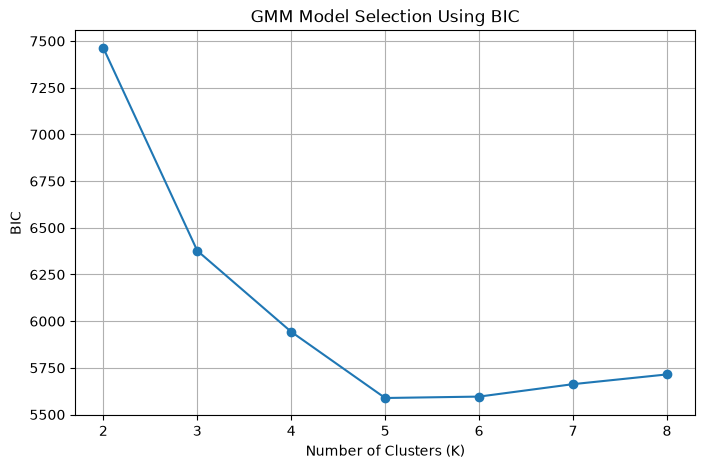

In [52]:
# Plot BIC values
plt.figure(figsize=(8, 5))
plt.plot(bic_df["K"], bic_df["BIC"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("BIC")
plt.title("GMM Model Selection Using BIC")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

In [53]:
# 4. Assign GMM clusters and calculate membership probabilities
probabilities = best_gmm.predict_proba(X_scaled)

df["GMM_cluster"] = best_gmm.predict(X_scaled)
df["GMM_max_probability"] = probabilities.max(axis=1)

# Customers with maximum membership probability below 0.60
uncertain_customers = df[df["GMM_max_probability"] < 0.60].copy()
uncertain_customers = uncertain_customers.sort_values(
    "GMM_max_probability"
)

print("\n--- Uncertain Customers (Maximum Probability < 0.60) ---")
print("Number of uncertain customers:", len(uncertain_customers))

columns_to_show = [
    "customer_id",
    "recency_days",
    "frequency",
    "monetary",
    "GMM_cluster",
    "GMM_max_probability"
]

if uncertain_customers.empty:
    print("No customers have a maximum membership probability below 0.60.")
else:
    print(
        uncertain_customers[columns_to_show]
        .head(20)
        .round(3)
        .to_string(index=False)
    )
    print("\nShowing up to 20 uncertain customers.")


--- Uncertain Customers (Maximum Probability < 0.60) ---
Number of uncertain customers: 23
customer_id  recency_days  frequency  monetary  GMM_cluster  GMM_max_probability
  CUST00951            25          4  35775.40            2                0.468
  CUST00389            18          6  36466.33            2                0.474
  CUST00783            92          6  28028.98            0                0.491
  CUST00397           302          5   6036.29            4                0.501
  CUST00426            16          6  35899.73            2                0.511
  CUST00731            41         17  20727.79            2                0.512
  CUST00445           352          6    867.98            0                0.513
  CUST00904            67          4  32521.04            2                0.517
  CUST01118            22         11  31937.04            2                0.518
  CUST00919            24         14  24983.45            1                0.532
  CUST01217      

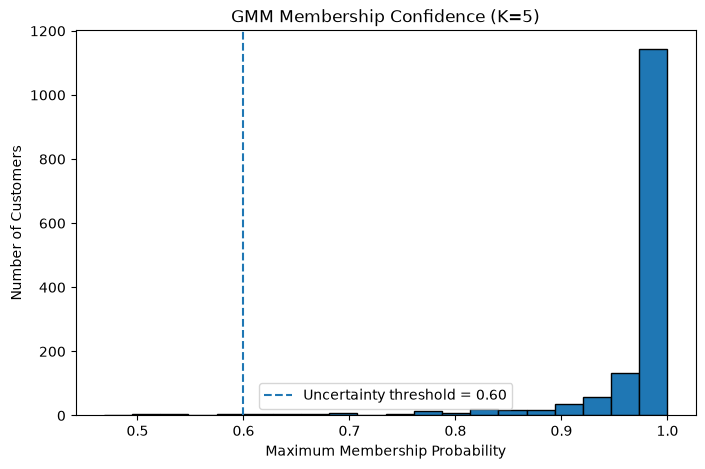

In [54]:
# Plot GMM membership confidence
plt.figure(figsize=(8, 5))
plt.hist(df["GMM_max_probability"], bins=20, edgecolor="black")
plt.axvline(
    0.60,
    linestyle="--",
    label="Uncertainty threshold = 0.60"
)
plt.xlabel("Maximum Membership Probability")
plt.ylabel("Number of Customers")
plt.title(f"GMM Membership Confidence (K={best_k})")
plt.legend()
plt.show()

In [55]:
# 5. Compare GMM's preferred K with Day 31's business choice
print("\n--- GMM vs Business Choice ---")
print("GMM BIC-preferred K:", best_k)
print("Day 31 business-preferred K: 5")

if best_k == 5:
    print("Both approaches prefer 5 clusters.")
else:
    print(
        f"The BIC-preferred K ({best_k}) differs from the "
        "business-preferred K (5)."
    )


--- GMM vs Business Choice ---
GMM BIC-preferred K: 5
Day 31 business-preferred K: 5
Both approaches prefer 5 clusters.


In [56]:
# 6. Run DBSCAN on the scaled RFM features
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

df["DBSCAN_cluster"] = dbscan_labels

# Noise points have label -1
noise_customers = df[df["DBSCAN_cluster"] == -1].copy()
cluster_labels = set(dbscan_labels) - {-1}
noise_count = len(noise_customers)

print("\n--- DBSCAN Results ---")
print("eps:", 0.5)
print("min_samples:", 5)
print("Number of clusters:", len(cluster_labels))
print("Number of noise customers:", noise_count)
print("Percentage of customers marked as noise:",
      round(noise_count / len(df) * 100, 2), "%")


--- DBSCAN Results ---
eps: 0.5
min_samples: 5
Number of clusters: 1
Number of noise customers: 8
Percentage of customers marked as noise: 0.53 %


In [57]:
# Count customers in each DBSCAN cluster
cluster_counts = (
    df["DBSCAN_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Customer_Count")
)

cluster_counts["Cluster"] = cluster_counts["Cluster"].replace(
    {-1: "Noise"}
)

print("\n--- DBSCAN Cluster Counts ---")
print(cluster_counts.to_string(index=False))


--- DBSCAN Cluster Counts ---
Cluster  Customer_Count
  Noise               8
      0            1492


In [58]:
# 7. Profile DBSCAN noise customers
print("\n--- DBSCAN Noise Customer Profile ---")

if noise_customers.empty:
    print("DBSCAN did not identify any noise customers.")
else:
    print("\nAverage RFM values for noise customers:")
    print(noise_customers[features].mean().round(2))

    print("\nAverage RFM values for all customers:")
    print(df[features].mean().round(2))

    print("\nFirst 20 noise customers:")
    print(
        noise_customers[
            ["customer_id"] + features
        ].head(20).round(2).to_string(index=False)
    )


--- DBSCAN Noise Customer Profile ---

Average RFM values for noise customers:
recency_days       81.50
frequency          13.12
monetary        71742.47
dtype: float64

Average RFM values for all customers:
recency_days      209.25
frequency           7.25
monetary        23671.26
dtype: float64

First 20 noise customers:
customer_id  recency_days  frequency  monetary
  CUST00266            89          8 103858.45
  CUST00543           299          1  32061.11
  CUST00616            93         10  92524.55
  CUST00670            14         10  79927.79
  CUST01160            32         11  83452.28
  CUST01173             8         29  24075.58
  CUST01335            99         11  81235.89
  CUST01436            18         25  76804.11


In [59]:
# 8. Compare average RFM values across DBSCAN clusters
print("\n--- RFM Profile by DBSCAN Cluster ---")
profile = df.groupby("DBSCAN_cluster")[features].mean().round(2)
print(profile)


--- RFM Profile by DBSCAN Cluster ---
                recency_days  frequency  monetary
DBSCAN_cluster                                   
-1                     81.50      13.12  71742.47
 0                    209.93       7.22  23413.51


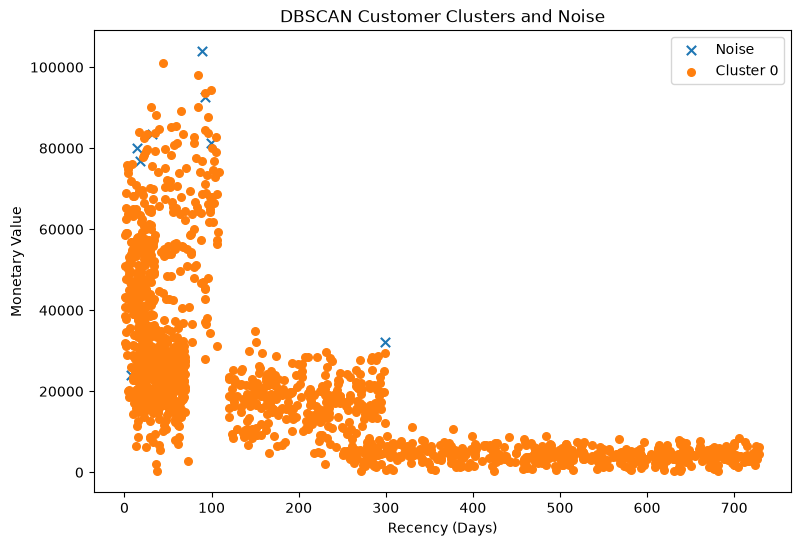

In [60]:
# 9. Plot DBSCAN results using recency and monetary value
plt.figure(figsize=(9, 6))

for cluster in sorted(df["DBSCAN_cluster"].unique()):
    subset = df[df["DBSCAN_cluster"] == cluster]

    if cluster == -1:
        plt.scatter(
            subset["recency_days"],
            subset["monetary"],
            label="Noise",
            marker="x",
            s=45
        )
    else:
        plt.scatter(
            subset["recency_days"],
            subset["monetary"],
            label=f"Cluster {cluster}",
            s=30
        )

plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value")
plt.title("DBSCAN Customer Clusters and Noise")
plt.legend()
plt.show()

- GMM was evaluated for K values from 2 to 8 using the Bayesian Information Criterion (BIC). The lowest BIC was obtained at **K = 5 (5588.63)**, matching the business-preferred choice from Day 31 of **K = 5**. This shows that the statistical model-selection result agrees with the business requirements.

- Customers whose maximum GMM membership probability was below 0.60 were identified as uncertain customers. **23 uncertain customers** were found. DBSCAN identified **1 cluster and 8 noise customers** using `eps=0.5` and `min_samples=5`. The average RFM values of noise customers were recency = **81.50 days**, frequency = **13.12**, and monetary value = **₹71,742.47**, compared with recency = **209.25 days**, frequency = **7.25**, and monetary value = **₹23,671.26** for all customers. This suggests that the noise group generally contains more recent and frequent customers with higher monetary values, although individual customers show different patterns.

Overall, GMM helps compare possible cluster counts and estimate membership confidence, while DBSCAN identifies dense customer groups and customers that do not fit those groups. In this experiment, GMM's preferred K matched the business choice of five clusters. DBSCAN found one main cluster and a small number of noise points with the selected parameters. The final method should be selected based on both the clustering results and the business objective.

### 1. Comparison of Clustering Methods

| Method | Main Assumptions | Strengths | Weaknesses |
|---|---|---|---|
| **K-Means** | Clusters are generally compact and separated around their centres. | Simple, fast, and works well with large datasets. | Sensitive to outliers and cluster shape; requires the number of clusters (K). |
| **Hierarchical Clustering (Ward)** | Clusters should be compact, with low within-cluster variance. | Creates a hierarchy of clusters and works well for compact groups. | Can struggle with curved shapes and large datasets; requires a cluster count or distance threshold. |
| **Single Linkage** | Clusters are connected through their nearest points. | Can identify curved and non-spherical clusters, such as moons and circles. | Sensitive to the chaining effect, where bridge points can connect separate clusters. |
| **DBSCAN** | Clusters are dense regions separated by less-dense regions. | Finds irregularly shaped clusters and identifies noise points; does not require K in advance. | Sensitive to `eps` and `min_samples`; can struggle when clusters have different densities. |
| **Gaussian Mixture Model (GMM)** | Data can be represented as a mixture of Gaussian distributions. | Provides membership probabilities and can model overlapping or elliptical clusters. | Requires selecting the number of components and may struggle with strongly curved clusters. |

### 2. Decision Guide

- **Choose K-Means** when the dataset contains compact, well-separated clusters and speed is important.
- **Choose Ward linkage** when compact clusters are expected and a hierarchical clustering approach is useful.
- **Choose Single Linkage** when the data contains connected, curved shapes, but check for the chaining effect.
- **Choose DBSCAN** when the dataset may contain irregularly shaped clusters and outliers.
- **Choose GMM** when clusters may overlap and membership probabilities are important.

Before clustering, scale numerical features when they have different units or ranges. Compare the results using suitable evaluation metrics and business requirements.

### 3. Three Worked Examples from the Experiments

#### Example 1: Blobs Dataset

In Task 07, all five methods—K-Means, Ward, Single Linkage, DBSCAN, and GMM—achieved an Adjusted Rand Index (ARI) of **1.0000** on the blobs dataset.

**Interpretation:** The groups were well separated, so all five methods recovered the original clusters successfully in this experiment. For this type of data, K-Means is a reasonable choice because it is simple and efficient.

#### Example 2: Moons Dataset

In Task 07, Single Linkage achieved an ARI of **1.0000**, and DBSCAN achieved **0.9950**. K-Means, Ward, and GMM achieved ARI scores of approximately **0.475**.

**Interpretation:** The moons dataset contains curved clusters that are difficult for methods designed around compact or Gaussian-shaped groups. Single Linkage and DBSCAN performed much better in this experiment because they could identify the curved structure.

#### Example 3: Customer RFM Dataset

In Task 08, GMM selected **K = 5** using BIC, matching the business-preferred choice from Day 31. GMM identified **23 uncertain customers** whose maximum membership probability was below 0.60.

DBSCAN, using `eps=0.5` and `min_samples=5`, found one main cluster containing 1,492 customers and eight noise customers.

**Interpretation:** GMM was useful for comparing the number of customer segments and identifying uncertain assignments. However, DBSCAN's selected parameters produced only one main cluster, so its result may not be sufficiently useful for detailed customer segmentation without further parameter tuning.

### 4. Is There One Best Clustering Method?

There is no single best clustering method for every dataset. The most suitable method depends on the shape, density, distribution, size, and purpose of the data.

For example, K-Means performed very well on the blobs dataset, while Single Linkage and DBSCAN performed better on the moons dataset. GMM was useful for customer segmentation because it provided membership probabilities and a BIC-based comparison of cluster counts.

Therefore, I would compare multiple methods and select the one that provides useful, reliable, and interpretable results for the particular problem.

### 5. When Should We Compare Two Methods?

I would compare two clustering methods when the dataset's structure is unclear or when different methods may produce different results.

For example, I would compare **K-Means and DBSCAN** on a dataset that may contain both compact groups and outliers. K-Means can provide a simple partition when the number of groups is known, while DBSCAN can identify dense regions and noise without requiring a predefined cluster count.

I would then compare the cluster assignments, evaluation scores where ground-truth labels are available, the number of clusters, the number of noise points, and the usefulness of the results for the business problem.